# Option pricing and delta hedging: results

This notebook reproduces every number and plot in the README.
Run all cells from top to bottom. It takes well under a minute, and the seeds
are fixed, so you get the same numbers every time. Plots are saved to `../figures/`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from optionlab import black_scholes as bs
from optionlab.monte_carlo import mc_price
from optionlab.hedging import delta_hedge_pnl, simulate_paths

# One option used in every experiment: an at-the-money one-year call.
S0, K, T, r, sigma = 100.0, 100.0, 1.0, 0.05, 0.20

# Plot style, set once.
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8983"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c9c8c2", "axes.labelcolor": "#52514e", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.8,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "lines.linewidth": 2, "legend.frameon": False, "figure.dpi": 110,
})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(f"../figures/{name}.png", dpi=160)

## 1. Black-Scholes price and Greeks

The closed-form numbers that everything else is compared against.

In [2]:
for kind in ["call", "put"]:
    print(f"{kind:>4}  price {bs.price(S0, K, T, r, sigma, kind):8.4f}"
          f"  delta {bs.delta(S0, K, T, r, sigma, kind):7.4f}"
          f"  theta {bs.theta(S0, K, T, r, sigma, kind):8.4f}"
          f"  rho {bs.rho(S0, K, T, r, sigma, kind):8.4f}")
print(f"both  gamma {bs.gamma(S0, K, T, r, sigma):.5f}  vega {bs.vega(S0, K, T, r, sigma):.4f}")

bs_call = bs.price(S0, K, T, r, sigma, "call")

call  price  10.4506  delta  0.6368  theta  -6.4140  rho  53.2325
 put  price   5.5735  delta -0.3632  theta  -1.6579  rho -41.8905
both  gamma 0.01876  vega 37.5240


## 2. Monte Carlo convergence

Price the same call by simulation with more and more paths. The lines show the
width of the 95% confidence interval (1.96 standard errors), which is the error
we *expect*. The dots show the error we actually got against Black-Scholes.

antithetic=False  slope of log(SE) vs log(N): -0.500   BS inside 95% CI in 9 of 11 runs   SE at N=1,024,000: 0.01454
antithetic=True   slope of log(SE) vs log(N): -0.500   BS inside 95% CI in 9 of 11 runs   SE at N=1,024,000: 0.01029
plain SE / antithetic SE, average over all N: 1.41  (variance reduction factor 1.99)


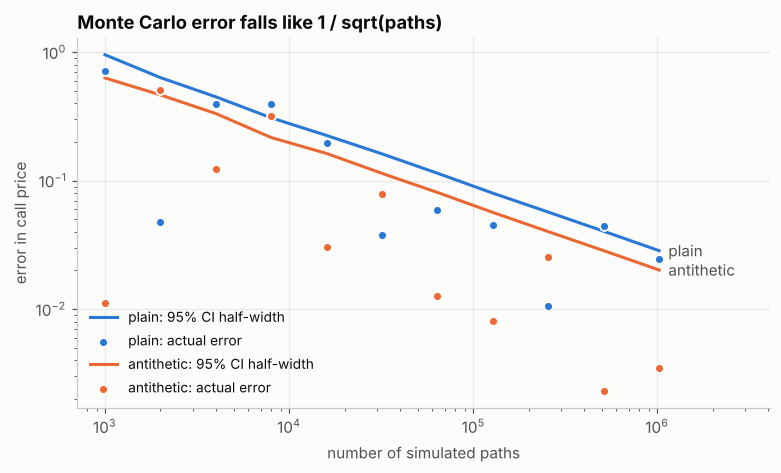

In [3]:
path_counts = [1000 * 2**k for k in range(11)]   # 1,000 up to 1,024,000

rows = {False: [], True: []}
for antithetic in [False, True]:
    for i, n in enumerate(path_counts):
        estimate, se, lo, hi = mc_price(S0, K, T, r, sigma, n, "call", antithetic, seed=100 + i)
        rows[antithetic].append((n, estimate, se, abs(estimate - bs_call), lo < bs_call < hi))

fig, ax = plt.subplots(figsize=(7.2, 4.4))
for antithetic, colour, label in [(False, BLUE, "plain"), (True, ORANGE, "antithetic")]:
    n, est, se, err, inside = map(np.array, zip(*rows[antithetic]))
    ax.plot(n, 1.96 * se, color=colour, label=f"{label}: 95% CI half-width")
    ax.scatter(n, err, color=colour, s=34, edgecolor="#fcfcfb", linewidth=1.2, zorder=3,
               label=f"{label}: actual error")
    ax.annotate(label, (n[-1], 1.96 * se[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", color="#52514e")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(right=path_counts[-1] * 4)
ax.set_xlabel("number of simulated paths"); ax.set_ylabel("error in call price")
ax.set_title("Monte Carlo error falls like 1 / sqrt(paths)")
ax.legend(loc="lower left", fontsize=9)
save(fig, "mc_convergence")

for antithetic in [False, True]:
    n, est, se, err, inside = map(np.array, zip(*rows[antithetic]))
    slope = np.polyfit(np.log(n), np.log(se), 1)[0]
    print(f"antithetic={antithetic!s:5}  slope of log(SE) vs log(N): {slope:.3f}"
          f"   BS inside 95% CI in {inside.sum()} of {len(inside)} runs"
          f"   SE at N=1,024,000: {se[-1]:.5f}")
ratio = np.array([row[2] for row in rows[False]]) / np.array([row[2] for row in rows[True]])
print(f"plain SE / antithetic SE, average over all N: {ratio.mean():.2f}"
      f"  (variance reduction factor {ratio.mean()**2:.2f})")

### Does the 95% confidence interval really cover 95% of the time?

Eleven runs are too few to judge that, so repeat a small pricing run 2,000
times with different seeds and count how often Black-Scholes is inside.

In [4]:
REPEATS = 2000
for antithetic in [False, True]:
    hits = 0
    for seed in range(REPEATS):
        estimate, se, lo, hi = mc_price(S0, K, T, r, sigma, 10_000, "call", antithetic, seed=seed)
        hits += lo < bs_call < hi
    print(f"antithetic={antithetic!s:5}  Black-Scholes inside the 95% CI in {hits / REPEATS:.1%} of {REPEATS} runs")

antithetic=False  Black-Scholes inside the 95% CI in 94.8% of 2000 runs


antithetic=True   Black-Scholes inside the 95% CI in 94.2% of 2000 runs


## 3. Delta hedging a short call

We sell the call for its Black-Scholes price and hedge with the correct
volatility. First a comparison with not hedging at all, then the P&L
distribution for weekly and daily rebalancing.

premium received: 10.4506
unhedged               mean   0.177   std 15.290   5% worst -31.792   min -121.189
hedged weekly (52)     mean  -0.000   std  0.955   5% worst  -1.565   min   -5.844
hedged daily (252)     mean  -0.001   std  0.436   5% worst  -0.715   min   -2.699


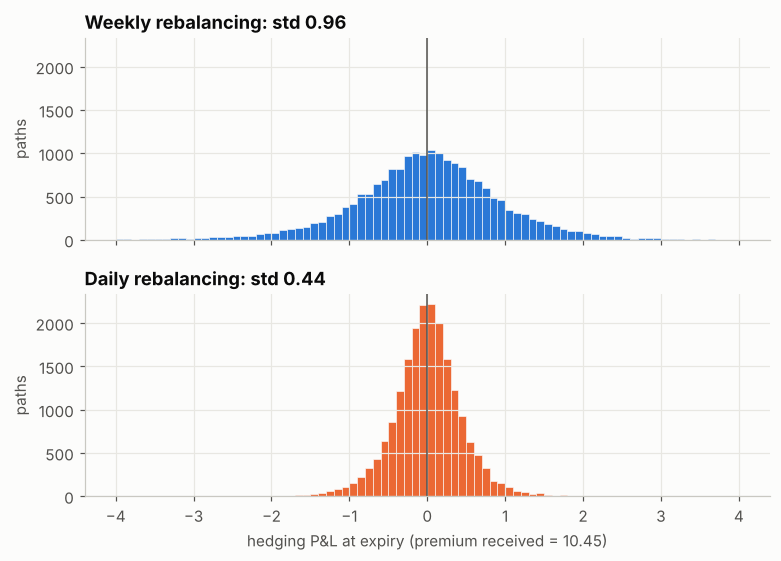

In [5]:
N_PATHS = 20_000

rng = np.random.default_rng(7)
ST = simulate_paths(S0, T, r, sigma, 1, N_PATHS, rng)[:, -1]
unhedged = bs_call * np.exp(r * T) - np.maximum(ST - K, 0.0)

weekly = delta_hedge_pnl(S0, K, T, r, sigma, n_steps=52, n_paths=N_PATHS, seed=7)
daily = delta_hedge_pnl(S0, K, T, r, sigma, n_steps=252, n_paths=N_PATHS, seed=7)

def describe(name, pnl):
    print(f"{name:<22} mean {pnl.mean():7.3f}   std {pnl.std():6.3f}"
          f"   5% worst {np.percentile(pnl, 5):7.3f}   min {pnl.min():8.3f}")

print(f"premium received: {bs_call:.4f}")
describe("unhedged", unhedged)
describe("hedged weekly (52)", weekly)
describe("hedged daily (252)", daily)

fig, axes = plt.subplots(2, 1, figsize=(7.2, 5.2), sharex=True, sharey=True)
bins = np.linspace(-4, 4, 81)
for ax, pnl, colour, name in [(axes[0], weekly, BLUE, "Weekly rebalancing"),
                              (axes[1], daily, ORANGE, "Daily rebalancing")]:
    ax.hist(pnl, bins=bins, color=colour, edgecolor="#fcfcfb", linewidth=0.4)
    ax.axvline(0, color="#52514e", linewidth=1)
    ax.set_title(f"{name}: std {pnl.std():.2f}")
    ax.set_ylabel("paths")
axes[1].set_xlabel("hedging P&L at expiry (premium received = %.2f)" % bs_call)
save(fig, "hedging_pnl_hist")

### Hedging error against rebalancing frequency

Repeat for several rebalancing frequencies and plot the standard deviation of
the P&L. The dashed line is a known approximation for the hedging error,
`sqrt(pi/4) * vega * sigma / sqrt(n)` (Derman and Kamal, 1999). It is not
fitted to our data.

n_steps    4   mean -0.0185   std 3.1692   std as % of premium  30.3%
n_steps   12   mean  0.0019   std 1.9171   std as % of premium  18.3%
n_steps   26   mean  0.0120   std 1.3308   std as % of premium  12.7%
n_steps   52   mean  0.0090   std 0.9507   std as % of premium   9.1%


n_steps  126   mean -0.0004   std 0.6216   std as % of premium   5.9%


n_steps  252   mean -0.0027   std 0.4372   std as % of premium   4.2%


n_steps  504   mean -0.0050   std 0.3125   std as % of premium   3.0%
slope of log(std) vs log(n_steps): -0.481  (theory: -0.5)
simulated / approximation: [0.953 0.999 1.02  1.031 1.049 1.043 1.055]


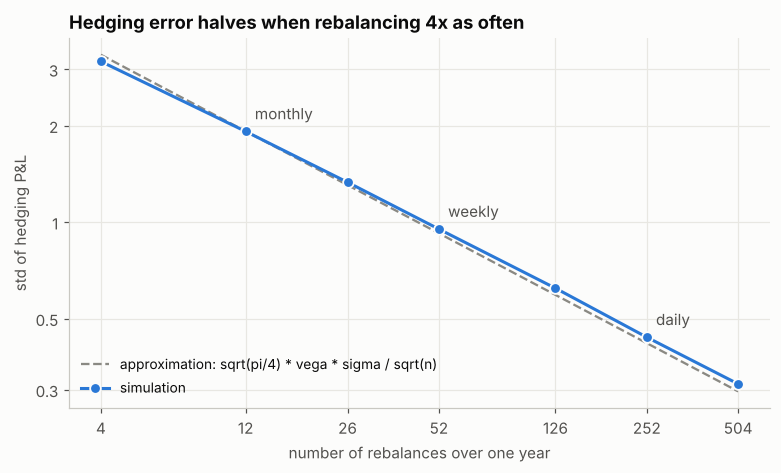

In [6]:
step_counts = [4, 12, 26, 52, 126, 252, 504]
names = {12: "monthly", 52: "weekly", 252: "daily"}

stds = []
for n_steps in step_counts:
    pnl = delta_hedge_pnl(S0, K, T, r, sigma, n_steps=n_steps, n_paths=N_PATHS, seed=11)
    stds.append(pnl.std())
    print(f"n_steps {n_steps:4d}   mean {pnl.mean():7.4f}   std {pnl.std():.4f}"
          f"   std as % of premium {100 * pnl.std() / bs_call:5.1f}%")
stds = np.array(stds)

approx = np.sqrt(np.pi / 4) * bs.vega(S0, K, T, r, sigma) * sigma / np.sqrt(step_counts)
slope = np.polyfit(np.log(step_counts), np.log(stds), 1)[0]
print(f"slope of log(std) vs log(n_steps): {slope:.3f}  (theory: -0.5)")
print("simulated / approximation:", np.round(stds / approx, 3))

fig, ax = plt.subplots(figsize=(7.2, 4.4))
ax.plot(step_counts, approx, color=GREY, linestyle="--", linewidth=1.5,
        label="approximation: sqrt(pi/4) * vega * sigma / sqrt(n)")
ax.plot(step_counts, stds, color=BLUE, marker="o", markersize=7,
        markeredgecolor="#fcfcfb", markeredgewidth=1.2, label="simulation")
for n_steps, s in zip(step_counts, stds):
    if n_steps in names:
        ax.annotate(names[n_steps], (n_steps, s), xytext=(6, 8), textcoords="offset points",
                    color="#52514e")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xticks(step_counts); ax.set_xticklabels(step_counts); ax.minorticks_off()
ax.set_yticks([0.3, 0.5, 1, 2, 3]); ax.set_yticklabels(["0.3", "0.5", "1", "2", "3"])
ax.set_xlabel("number of rebalances over one year"); ax.set_ylabel("std of hedging P&L")
ax.set_title("Hedging error halves when rebalancing 4x as often")
ax.legend(loc="lower left", fontsize=9)
save(fig, "hedging_error_vs_frequency")

## 4. Model risk: hedging with the wrong volatility

The stock really moves with 20% volatility. Our model uses a different number
for both the premium we charge and every delta we compute. Rebalancing is
daily, so what is left is mostly the effect of the wrong model.

In [7]:
hedge_vols = np.array([0.10, 0.125, 0.15, 0.175, 0.20, 0.225, 0.25, 0.275, 0.30])

results = {}
for sigma_hedge in hedge_vols:
    results[sigma_hedge] = delta_hedge_pnl(S0, K, T, r, sigma, n_steps=252, n_paths=N_PATHS,
                                           sigma_hedge=sigma_hedge, seed=21)

# Average P&L we expect in theory: the premium we charged minus the true price,
# grown to expiry at the risk-free rate.
theory = (bs.price(S0, K, T, r, hedge_vols) - bs_call) * np.exp(r * T)
vega_estimate = bs.vega(S0, K, T, r, sigma) * (hedge_vols - sigma)

print("hedge vol   mean P&L   theory   vega*dvol     std    5% worst   share of paths losing")
for sigma_hedge, th, ve in zip(hedge_vols, theory, vega_estimate):
    pnl = results[sigma_hedge]
    print(f"   {sigma_hedge:5.1%}   {pnl.mean():8.3f}  {th:7.3f}   {ve:8.3f}  {pnl.std():6.3f}"
          f"   {np.percentile(pnl, 5):8.3f}   {np.mean(pnl < 0):6.1%}")

hedge vol   mean P&L   theory   vega*dvol     std    5% worst   share of paths losing
   10.0%     -3.838   -3.833     -3.752   2.100     -7.553   100.0%
   12.5%     -2.912   -2.909     -2.814   1.484     -5.521   100.0%
   15.0%     -1.956   -1.954     -1.876   0.978     -3.706   100.0%
   17.5%     -0.983   -0.982     -0.938   0.597     -2.106    99.2%
   20.0%     -0.000    0.000      0.000   0.437     -0.721    49.7%
   22.5%      0.990    0.989      0.938   0.563      0.206     1.2%
   25.0%      1.983    1.982      1.876   0.799      0.786     0.0%
   27.5%      2.979    2.978      2.814   1.044      1.344     0.0%
   30.0%      3.976    3.975      3.752   1.274      1.933     0.0%


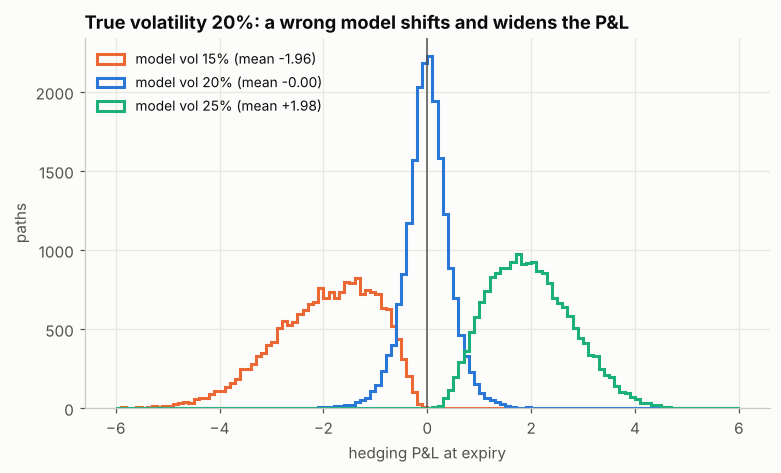

In [8]:
fig, ax = plt.subplots(figsize=(7.2, 4.4))
bins = np.linspace(-6, 6, 121)
for sigma_hedge, colour in [(0.15, ORANGE), (0.20, BLUE), (0.25, AQUA)]:
    pnl = results[sigma_hedge]
    ax.hist(pnl, bins=bins, histtype="step", linewidth=2, color=colour,
            label=f"model vol {sigma_hedge:.0%} (mean {pnl.mean():+.2f})")
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_xlabel("hedging P&L at expiry"); ax.set_ylabel("paths")
ax.set_title("True volatility 20%: a wrong model shifts and widens the P&L")
ax.legend(loc="upper left", fontsize=9)
save(fig, "model_risk_distributions")

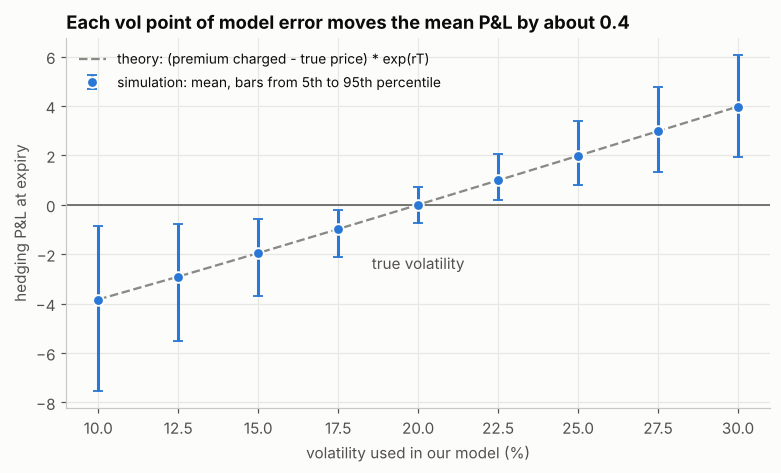

In [9]:
means = np.array([results[v].mean() for v in hedge_vols])
p05 = np.array([np.percentile(results[v], 5) for v in hedge_vols])
p95 = np.array([np.percentile(results[v], 95) for v in hedge_vols])

fig, ax = plt.subplots(figsize=(7.2, 4.4))
ax.axhline(0, color="#52514e", linewidth=1)
ax.plot(100 * hedge_vols, theory, color=GREY, linestyle="--", linewidth=1.5,
        label="theory: (premium charged - true price) * exp(rT)")
ax.errorbar(100 * hedge_vols, means, yerr=[means - p05, p95 - means], fmt="o", color=BLUE,
            markersize=7, markeredgecolor="#fcfcfb", markeredgewidth=1.2, elinewidth=2,
            capsize=3, label="simulation: mean, bars from 5th to 95th percentile")
ax.annotate("true volatility", (20, 0), xytext=(0, -42), textcoords="offset points",
            ha="center", color="#52514e")
ax.set_xlabel("volatility used in our model (%)"); ax.set_ylabel("hedging P&L at expiry")
ax.set_title("Each vol point of model error moves the mean P&L by about 0.4")
ax.legend(loc="upper left", fontsize=9)
save(fig, "model_risk_mean")